In [1]:
# -------------------------------------------------------------------
# DeltaT = Nf * dt sensitivity sweep, using saved 1-year TD reference
# -------------------------------------------------------------------

# IMPORTANT:
# This cell must be run from a fresh kernel, before importing WDM, jax,
# or WDM_LISAresponse modules.

import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["JAX_PLATFORM_NAME"] = "cpu"

# Verify JAX backend before importing WDM / response code
import jax

print("JAX devices:", jax.devices())
print("JAX default backend:", jax.default_backend())

if jax.default_backend() != "cpu":
    raise RuntimeError(
        "JAX is not using CPU. Restart the kernel and run this cell before any other imports."
    )

import gc
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import WDM

from pathlib import Path

from lisaorbits.file import read_orbit_file
from lisaorbits import InterpolatedOrbits

from WDM_LISAresponse.code.lisa_response.TDI import gen2_michelson_wdm

from WDM_LISAresponse.code.utils.utils import (
    compute_wdm_cut_info,
    apply_wdm_cut,
    wdm_mismatch,
)

# -------------------------------------------------------------------
# Where saved TD reference lives
# -------------------------------------------------------------------

BASE_OUTPUT_DIR = Path("runs")  # change if your OUTPUT_DIR is elsewhere

# If you know the exact directory, set it explicitly:
# TD_SAVE_DIR = Path("runs/<your_main_validation_run>/td_reference")
# td_meta_path = max(TD_SAVE_DIR.glob("td_reference_metadata_*.json"), key=lambda p: p.stat().st_mtime)

# Otherwise, search recursively for saved TD metadata files.
metadata_files = list(BASE_OUTPUT_DIR.rglob("td_reference_metadata_*.json"))

if len(metadata_files) == 0:
    raise FileNotFoundError(
        f"No td_reference_metadata_*.json files found under {BASE_OUTPUT_DIR.resolve()}"
    )

# Use newest metadata file by modification time
td_meta_path = max(metadata_files, key=lambda p: p.stat().st_mtime)

with open(td_meta_path, "r") as f:
    td_metadata = json.load(f)

TD_SAVE_DIR = td_meta_path.parent

print()
print("Using TD metadata:", td_meta_path)
print("TD save directory:", TD_SAVE_DIR)

# Quick metadata sanity check
print()
print("Metadata keys:", sorted(td_metadata.keys()))

if "saved_files" not in td_metadata:
    raise KeyError("Metadata file does not contain 'saved_files'.")

required_saved = ["td_xyz", "td_one_arm_links"]

for key in required_saved:
    if key not in td_metadata["saved_files"]:
        raise KeyError(f"Metadata saved_files does not contain required key: {key}")

print()
print("Saved TD arrays:", td_metadata["saved_files"]["td_xyz"])
print("Saved one-arm links:", td_metadata["saved_files"]["td_one_arm_links"])

# -------------------------------------------------------------------
# Sweep output directory
# -------------------------------------------------------------------

DELTA_T_SWEEP_DIR = TD_SAVE_DIR.parent / "deltaT_sensitivity_1yr"
DELTA_T_SWEEP_DIR.mkdir(parents=True, exist_ok=True)

print()
print("Sweep output directory:", DELTA_T_SWEEP_DIR)

JAX devices: [CpuDevice(id=0)]
JAX default backend: cpu

Using TD metadata: runs/emri_01yr_td_Nf500_dt10/td_reference/td_reference_metadata_lagblock_L25_R2048_B32_ip16_no_m0_20260612_163228.json
TD save directory: runs/emri_01yr_td_Nf500_dt10/td_reference

Metadata keys: ['N_original', 'N_padded', 'alpha', 'array_shapes', 'compressed_npz', 'created_at', 'dt', 'duration_yr', 'method_label', 'pad_info', 'run_name', 'saved_files', 'td_runtime_seconds', 'td_settings', 'tukey_factor', 'wdm_settings_for_later_comparison']

Saved TD arrays: runs/emri_01yr_td_Nf500_dt10/td_reference/td_xyz_lagblock_L25_R2048_B32_ip16_no_m0_20260612_163228.npz
Saved one-arm links: runs/emri_01yr_td_Nf500_dt10/td_reference/td_one_arm_links_lagblock_L25_R2048_B32_ip16_no_m0_20260612_163228.npz

Sweep output directory: runs/emri_01yr_td_Nf500_dt10/deltaT_sensitivity_1yr


In [21]:
# -------------------------------------------------------------------
# Stable WDM mismatch with audit diagnostics
# -------------------------------------------------------------------

import numpy as np
import inspect

_mismatch_audit = {
    "calls": 0,
    "labels": [
        "X uncut", "X cut",
        "Y uncut", "Y cut",
        "Z uncut", "Z cut",
        "link_12 uncut", "link_12 cut",
    ],
}


def _array_report_for_error(name, arr):
    arr = np.asarray(arr)
    return (
        f"{name}: shape={arr.shape}, dtype={arr.dtype}, "
        f"finite={np.isfinite(arr).sum()}/{arr.size}, "
        f"nan={np.isnan(arr).sum()}, inf={np.isinf(arr).sum()}"
    )


def wdm_mismatch_stable(w1, w2):
    """
    Phase-maximized WDM mismatch, computed stably.

    Same mathematical quantity as:

        mismatch = 1 - |<w1,w2>| / sqrt(<w1,w1><w2,w2>)

    but evaluated through the equivalent normalized residual norm.
    """
    call_index = _mismatch_audit["calls"]
    _mismatch_audit["calls"] += 1

    if call_index < len(_mismatch_audit["labels"]):
        label = _mismatch_audit["labels"][call_index]
    else:
        label = f"call {call_index}"

    w1_original = w1
    w2_original = w2

    w1 = np.asarray(w1, dtype=np.complex128).ravel()
    w2 = np.asarray(w2, dtype=np.complex128).ravel()

    if w1.shape != w2.shape:
        raise ValueError(
            f"Mismatch failure at {label}: shape mismatch "
            f"{w1.shape} vs {w2.shape}"
        )

    if not np.all(np.isfinite(w1)):
        raise ValueError(
            f"Mismatch failure at {label}: w1 has NaN/Inf\n"
            + _array_report_for_error("w1 original", w1_original)
        )

    if not np.all(np.isfinite(w2)):
        raise ValueError(
            f"Mismatch failure at {label}: w2 has NaN/Inf\n"
            + _array_report_for_error("w2 original", w2_original)
        )

    n1 = np.real(np.vdot(w1, w1))
    n2 = np.real(np.vdot(w2, w2))

    if not np.isfinite(n1) or not np.isfinite(n2) or n1 <= 0.0 or n2 <= 0.0:
        raise ValueError(
            f"Mismatch failure at {label}: bad norms\n"
            f"  n1={n1}\n"
            f"  n2={n2}\n"
            + _array_report_for_error("w1 original", w1_original) + "\n"
            + _array_report_for_error("w2 original", w2_original)
        )

    w1_hat = w1 / np.sqrt(n1)
    w2_hat = w2 / np.sqrt(n2)

    c = np.vdot(w1_hat, w2_hat)

    if not np.isfinite(c):
        raise ValueError(
            f"Mismatch failure at {label}: bad normalized cross product\n"
            f"  c={c}\n"
            f"  abs(c)={np.abs(c)}"
        )

    # Phase-maximize by rotating w2.
    if np.abs(c) > 0.0:
        w2_hat = w2_hat * np.exp(-1j * np.angle(c))

    diff = w1_hat - w2_hat
    mismatch = 0.5 * np.real(np.vdot(diff, diff))

    if not np.isfinite(mismatch):
        raise ValueError(
            f"Mismatch failure at {label}: non-finite mismatch\n"
            f"  mismatch={mismatch}\n"
            f"  raw abs overlap={np.abs(c)}"
        )

    if mismatch < 0.0:
        if abs(mismatch) < 1e-15:
            mismatch = 0.0
        else:
            raise ValueError(
                f"Mismatch failure at {label}: negative mismatch\n"
                f"  mismatch={mismatch}\n"
                f"  raw abs overlap={np.abs(c)}"
            )

    overlap = 1.0 - mismatch

    print(
        f"[mismatch_pair] {label}: "
        f"raw_abs_overlap={np.abs(c):.16e}, "
        f"stable_mismatch={mismatch:.16e}"
    )

    return float(overlap), float(mismatch)


# This is the global name used by run_deltaT_case.
def mismatch_pair(w_ref, w_test):
    return wdm_mismatch_stable(w_ref, w_test)


print("Active mismatch_pair reset.")
print("mismatch_pair source:")
print(inspect.getsource(mismatch_pair))

Active mismatch_pair reset.
mismatch_pair source:
def mismatch_pair(w_ref, w_test):
    return wdm_mismatch_stable(w_ref, w_test)



In [18]:
# -------------------------------------------------------------------
# Verify active mismatch function
# -------------------------------------------------------------------

import inspect

print(inspect.getsource(mismatch_pair))

def mismatch_pair(w_ref, w_test):
    return wdm_mismatch_stable(w_ref, w_test)



In [2]:
metadata_rows = []

for path in sorted(BASE_OUTPUT_DIR.rglob("td_reference_metadata_*.json")):
    with open(path, "r") as f:
        meta = json.load(f)

    pad = meta.get("pad_info", {})
    original_length = pad.get("original_length", meta.get("N_original", None))
    dt_meta = meta.get("dt", None)

    duration_years = None
    if original_length is not None and dt_meta is not None:
        duration_years = float(original_length) * float(dt_meta) / (365.25 * 24 * 3600)

    metadata_rows.append({
        "path": str(path),
        "original_length": original_length,
        "dt": dt_meta,
        "duration_years": duration_years,
        "alpha": meta.get("alpha", pad.get("alpha", None)),
        "tukey_factor": meta.get("tukey_factor", pad.get("tukey_factor", None)),
        "mtime": path.stat().st_mtime,
    })

df_metadata = pd.DataFrame(metadata_rows)
df_metadata = df_metadata.sort_values("duration_years", ascending=False)

display(df_metadata)

,path,original_length,dt,duration_years,alpha,tukey_factor,mtime
1,runs/emri_1yr_td_Nf500_dt10/td_reference/td_re...,3155814,10.0,1.000017,0.005,4.0,1.781267e+09
0,runs/emri_01yr_td_Nf500_dt10/td_reference/td_r...,315581,10.0,0.100002,0.005,4.0,1.781278e+09


In [3]:
# -------------------------------------------------------------------
# Explicitly select the 1-year TD reference metadata
# -------------------------------------------------------------------

TD_SAVE_DIR = Path("runs/emri_1yr_td_Nf500_dt10/td_reference")

metadata_files = sorted(TD_SAVE_DIR.glob("td_reference_metadata_*.json"))

if len(metadata_files) == 0:
    raise FileNotFoundError(f"No metadata files found in {TD_SAVE_DIR}")

# If there is only one metadata file, this is fine.
# If there are several, take the newest within the 1-year directory.
td_meta_path = max(metadata_files, key=lambda p: p.stat().st_mtime)

with open(td_meta_path, "r") as f:
    td_metadata = json.load(f)

print("Using TD metadata:", td_meta_path)
print("TD save directory:", TD_SAVE_DIR)

pad_info = td_metadata.get("pad_info", {})

print()
print("Sanity check:")
print("  original_length:", pad_info.get("original_length", td_metadata.get("N_original", None)))
print("  dt:", td_metadata.get("dt", None))
print("  alpha:", td_metadata.get("alpha", pad_info.get("alpha", None)))
print("  tukey_factor:", td_metadata.get("tukey_factor", pad_info.get("tukey_factor", None)))

duration_years = (
    float(pad_info.get("original_length", td_metadata.get("N_original")))
    * float(td_metadata.get("dt"))
    / (365.25 * 24 * 3600)
)

print("  duration_years:", duration_years)

if not (0.9 < duration_years < 1.1):
    raise RuntimeError("This does not look like a 1-year TD reference.")

Using TD metadata: runs/emri_1yr_td_Nf500_dt10/td_reference/td_reference_metadata_lagblock_L25_R2048_B32_ip16_no_m0_20260612_131537.json
TD save directory: runs/emri_1yr_td_Nf500_dt10/td_reference

Sanity check:
  original_length: 3155814
  dt: 10.0
  alpha: 0.005
  tukey_factor: 4.0
  duration_years: 1.0000171115674197


In [4]:
# -------------------------------------------------------------------
# Load saved 1-year TD reference arrays and one-arm links
# -------------------------------------------------------------------

saved_files = td_metadata["saved_files"]

td_arrays_path = Path(saved_files["td_xyz"])
td_links_path = Path(saved_files["td_one_arm_links"])

# If paths in metadata were saved as relative/old paths, fall back to TD_SAVE_DIR
if not td_arrays_path.exists():
    td_arrays_path = TD_SAVE_DIR / td_arrays_path.name

if not td_links_path.exists():
    td_links_path = TD_SAVE_DIR / td_links_path.name

if not td_arrays_path.exists():
    raise FileNotFoundError(f"Could not find TD arrays file: {td_arrays_path}")

if not td_links_path.exists():
    raise FileNotFoundError(f"Could not find TD one-arm links file: {td_links_path}")

print("Loading TD arrays from:", td_arrays_path)
print("Loading TD one-arm links from:", td_links_path)

td_arrays = np.load(td_arrays_path, allow_pickle=False)

times_pad = td_arrays["times_pad"]
hplus_td = td_arrays["hplus_td"]
hcross_td = td_arrays["hcross_td"]

X_td = td_arrays["X_td"]
Y_td = td_arrays["Y_td"]
Z_td = td_arrays["Z_td"]

td_links = np.load(td_links_path, allow_pickle=False)

print("Available one-arm links:", td_links.files)

if "dl_12" not in td_links.files:
    raise KeyError("dl_12 was not found in the saved one-arm link file.")

dl_12_td = td_links["dl_12"]

dt = float(times_pad[1] - times_pad[0])

print()
print("Loaded shapes:")
print("  times_pad:", times_pad.shape)
print("  hplus_td: ", hplus_td.shape)
print("  hcross_td:", hcross_td.shape)
print("  X_td:     ", X_td.shape)
print("  Y_td:     ", Y_td.shape)
print("  Z_td:     ", Z_td.shape)
print("  dl_12_td: ", dl_12_td.shape)

print()
print("dt:", dt)
print("Saved padded length:", len(times_pad))

duration_years_loaded = len(X_td) * dt / (365.25 * 24 * 3600)

print("Approx padded duration in years:", duration_years_loaded)

Loading TD arrays from: runs/emri_1yr_td_Nf500_dt10/td_reference/td_xyz_lagblock_L25_R2048_B32_ip16_no_m0_20260612_131537.npz
Loading TD one-arm links from: runs/emri_1yr_td_Nf500_dt10/td_reference/td_one_arm_links_lagblock_L25_R2048_B32_ip16_no_m0_20260612_131537.npz
Available one-arm links: ['times_pad', 'dl_21', 'dl_32', 'dl_13', 'dl_31', 'dl_23', 'dl_12']

Loaded shapes:
  times_pad: (3219000,)
  hplus_td:  (3219000,)
  hcross_td: (3219000,)
  X_td:      (3219000,)
  Y_td:      (3219000,)
  Z_td:      (3219000,)
  dl_12_td:  (3219000,)

dt: 10.0
Saved padded length: 3219000
Approx padded duration in years: 1.0200395467335919


In [5]:
# -------------------------------------------------------------------
# Remove old saved WDM-tail padding from the loaded TD arrays
# -------------------------------------------------------------------

def get_pad_info_value(pad_info, metadata, key, default=None):
    """
    Get a padding-related value from pad_info first, then metadata.
    """
    if key in pad_info:
        return pad_info[key]
    if key in metadata:
        return metadata[key]
    return default


# Check that the loaded arrays exist
required_names = [
    "td_metadata",
    "times_pad",
    "hplus_td",
    "hcross_td",
    "X_td",
    "Y_td",
    "Z_td",
    "dl_12_td",
]

missing = [name for name in required_names if name not in globals()]
if missing:
    raise NameError(
        "Missing required loaded variables. Run the TD-array loading cell first. "
        f"Missing: {missing}"
    )


pad_info = td_metadata.get("pad_info", {})

original_length_value = get_pad_info_value(
    pad_info,
    td_metadata,
    "original_length",
    default=None,
)

if original_length_value is None:
    raise KeyError("Could not find original_length in td_metadata or pad_info.")

original_length = int(original_length_value)

if "window_pad_left" not in pad_info or "window_pad_right" not in pad_info:
    raise KeyError(
        "Expected window_pad_left and window_pad_right in td_metadata['pad_info']."
    )

window_pad_left = int(pad_info["window_pad_left"])
window_pad_right = int(pad_info["window_pad_right"])

# Length after original physical signal + left/right window padding,
# but before the old Nf=500 WDM-tail padding.
post_window_length = original_length + window_pad_left + window_pad_right

old_saved_tail_right = len(times_pad) - post_window_length

if old_saved_tail_right < 0:
    raise ValueError(
        "Loaded TD arrays are shorter than original_length + window padding.\n"
        f"  len(times_pad)={len(times_pad)}\n"
        f"  original_length={original_length}\n"
        f"  window_pad_left={window_pad_left}\n"
        f"  window_pad_right={window_pad_right}\n"
        f"  post_window_length={post_window_length}"
    )

print("Saved TD length:              ", len(times_pad))
print("Original physical length:     ", original_length)
print("Window pad left:              ", window_pad_left)
print("Window pad right:             ", window_pad_right)
print("Post-window base length:      ", post_window_length)
print("Old saved WDM tail to remove: ", old_saved_tail_right)

# Trim old WDM-tail padding.
base_slice = slice(0, post_window_length)

times_base = times_pad[base_slice]
hplus_base = hplus_td[base_slice]
hcross_base = hcross_td[base_slice]

X_td_base = X_td[base_slice]
Y_td_base = Y_td[base_slice]
Z_td_base = Z_td[base_slice]

dl_12_td_base = dl_12_td[base_slice]

print()
print("Base arrays:")
print("  times_base:    ", times_base.shape)
print("  hplus_base:    ", hplus_base.shape)
print("  hcross_base:   ", hcross_base.shape)
print("  X_td_base:     ", X_td_base.shape)
print("  Y_td_base:     ", Y_td_base.shape)
print("  Z_td_base:     ", Z_td_base.shape)
print("  dl_12_td_base: ", dl_12_td_base.shape)

dt = float(times_base[1] - times_base[0])

print()
print("dt:", dt)

duration_years_base = original_length * dt / (365.25 * 24 * 3600)
print("Physical duration years:", duration_years_base)

# Sanity check for the one-year run
if not (0.9 < duration_years_base < 1.1):
    raise RuntimeError(
        "This does not look like the one-year reference. "
        f"duration_years_base={duration_years_base}"
    )

Saved TD length:               3219000
Original physical length:      3155814
Window pad left:               31559
Window pad right:              31559
Post-window base length:       3218932
Old saved WDM tail to remove:  68

Base arrays:
  times_base:     (3218932,)
  hplus_base:     (3218932,)
  hcross_base:    (3218932,)
  X_td_base:      (3218932,)
  Y_td_base:      (3218932,)
  Z_td_base:      (3218932,)
  dl_12_td_base:  (3218932,)

dt: 10.0
Physical duration years: 1.0000171115674197


In [6]:
# -------------------------------------------------------------------
# Recreate LISA orbit object and response settings
# -------------------------------------------------------------------

ORBIT_FILE = Path("esa-trailing-orbits.h5")  # change path if needed

if not ORBIT_FILE.exists():
    raise FileNotFoundError(
        f"Could not find orbit file: {ORBIT_FILE.resolve()}\n"
        "Set ORBIT_FILE to the correct path before continuing."
    )

orbit_data = read_orbit_file(str(ORBIT_FILE))
orbit_times = orbit_data.t0 + orbit_data.dt * np.arange(orbit_data.size)

orbits_trailing = InterpolatedOrbits(
    orbit_times,
    orbit_data.positions,
    orbit_data.velocities,
)

# Try to load sky location from metadata; otherwise use your validation defaults.
theta = float(td_metadata.get("theta", np.pi / 2))
phi = float(td_metadata.get("phi", 0.0))

print("Orbit file:", ORBIT_FILE)
print("theta:", theta)
print("phi:", phi)

# -------------------------------------------------------------------
# WDM / response parameters
# -------------------------------------------------------------------

wdm_settings = td_metadata.get("wdm_settings", {})

d = int(wdm_settings.get("d", 4))
A_frac = float(wdm_settings.get("A_frac", 0.25))

# For this sweep we are not calculating m=0.
CALC_M0 = False

# Fixed q for all Nf values.
# In your current fast no-m0 path this is mainly needed for consistency
# between the direct WDM response and the TD-reference WDM transform.
q_wdm = 1

# Same lag truncation as the main validation.
L_trunc_value = 25

METHOD_LABEL = "deltaT_sweep_adaptive_chunks_q1_no_m0"

# -------------------------------------------------------------------
# Adaptive WDM time-shift settings
# -------------------------------------------------------------------

FAST_TDI_ASSEMBLY_MODE = "batch_map"


def make_deltaT_shift_kwargs(Nf):
    """
    Adaptive chunking for the DeltaT sweep.

    The expensive temporary arrays in the variable time-shift assembly scale
    roughly like

        job_block_size * row_chunk_size * Nf * lag_block_size.

    Therefore, as Nf increases, we reduce row_chunk_size and lag_block_size.
    For larger Nf, we also switch to the job-blocked backend so that the
    directed-link jobs are processed more serially.
    """
    Nf = int(Nf)

    if Nf <= 500:
        backend = "lagfirst_chunked_lagblock"
        row_chunk_size = 2048
        lag_block_size = 32
        job_block_size = None

    elif Nf <= 1000:
        backend = "lagfirst_chunked_lagblock"
        row_chunk_size = 1024
        lag_block_size = 32
        job_block_size = None

    elif Nf <= 2000:
        backend = "lagfirst_chunked_lagblock"
        row_chunk_size = 512
        lag_block_size = 16
        job_block_size = None

    elif Nf <= 5000:
        backend = "lagfirst_chunked_lagblock_jobblock"
        row_chunk_size = 128
        lag_block_size = 8
        job_block_size = 1

    elif Nf <= 10000:
        backend = "lagfirst_chunked_lagblock_jobblock"
        row_chunk_size = 64
        lag_block_size = 4
        job_block_size = 1

    elif Nf <= 20000:
        backend = "lagfirst_chunked_lagblock_jobblock"
        row_chunk_size = 32
        lag_block_size = 4
        job_block_size = 1

    elif Nf <= 50000:
        backend = "lagfirst_chunked_lagblock_jobblock"
        row_chunk_size = 8
        lag_block_size = 2
        job_block_size = 1

    else:
        backend = "lagfirst_chunked_lagblock_jobblock"
        row_chunk_size = 4
        lag_block_size = 2
        job_block_size = 1

    kwargs = {
        "assembly_backend": backend,
        "assembly_precision": "complex64",
        "row_chunk_size": int(row_chunk_size),
        "lag_block_size": int(lag_block_size),
        "tl_tp_mode": "interp",
        "tl_tp_interp_points": 16,
        "tl_tp_interp_kind": "linear",
        "tl_tp_interp_backend": "auto",
        "batch_chunk": 1,
    }

    if job_block_size is not None:
        kwargs["job_block_size"] = int(job_block_size)

    return kwargs


# For backwards compatibility with older cells.
# Do not use these as fixed settings inside the sweep; they are only a default.
FAST_TDI_KWARGS = make_deltaT_shift_kwargs(500)
FAST_ONE_ARM_KWARGS = FAST_TDI_KWARGS.copy()

print()
print("WDM / response settings:")
print("  d:", d)
print("  A_frac:", A_frac)
print("  q_wdm:", q_wdm)
print("  calc_m0:", CALC_M0)
print("  L_trunc:", L_trunc_value)
print("  method label:", METHOD_LABEL)

print()
print("Default Nf=500 shift kwargs:")
for key, value in FAST_TDI_KWARGS.items():
    print(f"  {key}: {value}")

Orbit file: esa-trailing-orbits.h5
theta: 1.5707963267948966
phi: 0.0

WDM / response settings:
  d: 4
  A_frac: 0.25
  q_wdm: 1
  calc_m0: False
  L_trunc: 25
  method label: deltaT_sweep_adaptive_chunks_q1_no_m0

Default Nf=500 shift kwargs:
  assembly_backend: lagfirst_chunked_lagblock
  assembly_precision: complex64
  row_chunk_size: 2048
  lag_block_size: 32
  tl_tp_mode: interp
  tl_tp_interp_points: 16
  tl_tp_interp_kind: linear
  tl_tp_interp_backend: auto
  batch_chunk: 1


In [7]:
# -------------------------------------------------------------------
# Nf / DeltaT grid
# -------------------------------------------------------------------

# Full sweep, stopping at Nf = 10^4.
# With dt = 10 s, this gives DeltaT from 60 s to 1e5 s.
Nf_grid = [
    6, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 150, 200, 250, 300, 400, 
    500, 1000, 2000, 5000,
    10000,
]

# Pilot grid before running the full sweep.
Nf_grid_pilot = [
    500, 1000, 2000, 5000,
]

# All Nf values should be even.
bad_odd = [Nf for Nf in Nf_grid if Nf % 2 != 0]

if bad_odd:
    raise ValueError(f"All Nf values should be even. Odd values: {bad_odd}")


def wdm_target_length(n_samples, Nf):
    """
    Match the right-padding convention used by the WDM response path:
    target length is the next multiple of 2*Nf.
    """
    block = 2 * int(Nf)
    return int(np.ceil(int(n_samples) / block) * block)


def print_Nf_grid_summary(grid, label="Nf grid"):
    print(label + ":")

    for Nf in grid:
        Nf = int(Nf)

        target_length = wdm_target_length(len(times_pad), Nf)
        extra_pad = target_length - len(times_pad)
        Nt = target_length // Nf
        DeltaT = Nf * dt
        coeffs_per_channel = Nt * Nf

        msg = (
            f"  Nf={Nf:>6d}   "
            f"DeltaT={DeltaT:>12.3e} s   "
            f"Nt={Nt:>8d}   "
            f"target_length={target_length:>10d}   "
            f"extra_pad={extra_pad:>8d}   "
            f"coeffs/channel={coeffs_per_channel:>10,d}"
        )

        if "make_deltaT_shift_kwargs" in globals():
            kw = make_deltaT_shift_kwargs(Nf)
            msg += (
                f"   | backend={kw['assembly_backend']} "
                f"R={kw['row_chunk_size']} "
                f"B={kw['lag_block_size']} "
                f"J={kw.get('job_block_size', '-')}"
            )

        print(msg)


print_Nf_grid_summary(Nf_grid_pilot, label="Pilot grid")
print()
print_Nf_grid_summary(Nf_grid, label="Full grid")

Pilot grid:
  Nf=   500   DeltaT=   5.000e+03 s   Nt=    6438   target_length=   3219000   extra_pad=       0   coeffs/channel= 3,219,000   | backend=lagfirst_chunked_lagblock R=2048 B=32 J=-
  Nf=  1000   DeltaT=   1.000e+04 s   Nt=    3220   target_length=   3220000   extra_pad=    1000   coeffs/channel= 3,220,000   | backend=lagfirst_chunked_lagblock R=1024 B=32 J=-
  Nf=  2000   DeltaT=   2.000e+04 s   Nt=    1610   target_length=   3220000   extra_pad=    1000   coeffs/channel= 3,220,000   | backend=lagfirst_chunked_lagblock R=512 B=16 J=-
  Nf=  5000   DeltaT=   5.000e+04 s   Nt=     644   target_length=   3220000   extra_pad=    1000   coeffs/channel= 3,220,000   | backend=lagfirst_chunked_lagblock_jobblock R=128 B=8 J=1

Full grid:
  Nf=     6   DeltaT=   6.000e+01 s   Nt=  536500   target_length=   3219000   extra_pad=       0   coeffs/channel= 3,219,000   | backend=lagfirst_chunked_lagblock R=2048 B=32 J=-
  Nf=    10   DeltaT=   1.000e+02 s   Nt=  321900   target_length=   3

In [8]:
# -------------------------------------------------------------------
# Helper functions
# -------------------------------------------------------------------

def block_until_ready(x):
    """
    Force completion for JAX arrays; harmless for NumPy arrays.
    """
    if hasattr(x, "block_until_ready"):
        x.block_until_ready()
    return x


def materialize_xyz(xyz):
    """
    Convert X,Y,Z outputs to NumPy arrays after forcing JAX completion.
    """
    out = []

    for arr in xyz:
        block_until_ready(arr)
        out.append(np.asarray(arr))

    return tuple(out)


def pad_right_to_length(arr, target_length):
    """
    Right-pad a 1D time-domain array with zeros.
    """
    arr = np.asarray(arr)
    target_length = int(target_length)

    pad_right = target_length - len(arr)

    if pad_right < 0:
        raise ValueError(
            f"target_length={target_length} is shorter than input length={len(arr)}."
        )

    if pad_right == 0:
        return arr

    return np.pad(arr, (0, pad_right), mode="constant")


def make_td_reference_wdm_arrays(Nf, target_length=None):
    """
    Pad saved TD reference arrays to the same target length used by the
    direct WDM response, then transform them to WDM coefficients.

    Parameters
    ----------
    Nf:
        Number of WDM frequency bins.

    target_length:
        Optional target time-series length. If supplied, this should usually
        be inferred from the direct WDM output as

            target_length = X_wdm.shape[0] * Nf

        This guarantees that the TD-reference WDM transform uses the same
        coefficient grid as the direct WDM response.
    """
    Nf = int(Nf)

    if Nf % 2 != 0:
        raise ValueError(f"Nf must be even, got Nf={Nf}")

    if target_length is None:
        target_length = wdm_target_length(len(times_pad), Nf)

    target_length = int(target_length)

    if target_length % Nf != 0:
        raise ValueError(
            f"target_length={target_length} is not divisible by Nf={Nf}."
        )

    X_ref = pad_right_to_length(X_td, target_length)
    Y_ref = pad_right_to_length(Y_td, target_length)
    Z_ref = pad_right_to_length(Z_td, target_length)
    dl12_ref = pad_right_to_length(dl_12_td, target_length)

    wdm_ref = WDM.WDM.WDM_transform(
        dt=dt,
        Nf=Nf,
        N=target_length,
        q=q_wdm,
        d=d,
        calc_m0=CALC_M0,
        A_frac=A_frac,
    )

    X_td_w = wdm_ref.dwt(X_ref)
    Y_td_w = wdm_ref.dwt(Y_ref)
    Z_td_w = wdm_ref.dwt(Z_ref)
    dl12_td_w = wdm_ref.dwt(dl12_ref)

    return wdm_ref, X_td_w, Y_td_w, Z_td_w, dl12_td_w


def mismatch_pair(ref, app):
    """
    Compute mismatch between two WDM coefficient arrays.
    """
    ref = np.ravel(np.asarray(ref))
    app = np.ravel(np.asarray(app))

    if ref.shape != app.shape:
        raise ValueError(f"Shape mismatch in mismatch_pair: ref={ref.shape}, app={app.shape}")

    return wdm_mismatch(ref, app)


def extract_link_from_one_arm_cache(one_arm_cache, link=(1, 2), Nf=None):
    """
    Extract a directed one-arm WDM link from the cache populated by
    gen2_michelson_wdm.

    Expected cache payload format:
        value = (wdm_obj, link_map)

    where link_map contains keys such as (1, 2), (2, 1), etc.
    """
    candidates = []

    for key, value in one_arm_cache.items():
        if not isinstance(value, tuple) or len(value) != 2:
            continue

        wdm_obj, link_map = value

        if not isinstance(link_map, dict):
            continue

        if link not in link_map:
            continue

        if Nf is not None and int(wdm_obj.Nf) != int(Nf):
            continue

        candidates.append((key, wdm_obj, link_map[link]))

    if len(candidates) == 0:
        available = []

        for value in one_arm_cache.values():
            if isinstance(value, tuple) and len(value) == 2:
                _, maybe_link_map = value
                if isinstance(maybe_link_map, dict):
                    available.extend(list(maybe_link_map.keys()))

        raise KeyError(
            f"Could not find link {link} in one_arm_cache. "
            f"Available link keys found: {sorted(set(available))}"
        )

    # Use the last matching candidate.
    _, wdm_obj, link_arr = candidates[-1]

    return wdm_obj, link_arr


def clear_jax_memory():
    """
    Clear JAX compilation caches between large-Nf runs when possible.
    """
    try:
        import jax
        jax.clear_caches()
    except Exception:
        pass

    gc.collect()

In [9]:
# -------------------------------------------------------------------
# Boundary cut helper for varying Nf on base TD arrays
# -------------------------------------------------------------------

def get_pad_info_value(pad_info, metadata, key, default=None):
    """
    Get a padding-related value from pad_info first, then metadata.
    """
    if key in pad_info:
        return pad_info[key]
    if key in metadata:
        return metadata[key]
    return default


def make_fixed_saved_grid_cut_info(Nf, wdm_ref):
    """
    Boundary cut for varying Nf after removing the old saved WDM-tail padding.

    The base TD arrays contain:

        original signal
      + left/right Tukey-window padding

    They do NOT contain the old Nf=500 WDM-tail padding.

    For a new Nf, the WDM transform may require new right padding.

    Therefore the right cut samples are:

        taper margin
      + original right window padding
      + new Nf-specific right WDM tail

    We call compute_wdm_cut_info with include_wdm_tail_padding=False,
    because the new WDM tail has already been included explicitly in
    effective_window_pad_right.
    """
    Nf = int(Nf)

    pad_info = td_metadata.get("pad_info", {})

    original_length_value = get_pad_info_value(
        pad_info,
        td_metadata,
        "original_length",
        default=None,
    )

    if original_length_value is None:
        raise KeyError(
            "Could not find original_length in td_metadata['pad_info'] "
            "or td_metadata."
        )

    original_length = int(original_length_value)

    if "window_pad_left" not in pad_info or "window_pad_right" not in pad_info:
        raise KeyError(
            "Expected 'window_pad_left' and 'window_pad_right' in "
            "td_metadata['pad_info']."
        )

    window_pad_left = int(pad_info["window_pad_left"])
    window_pad_right = int(pad_info["window_pad_right"])

    post_window_length = original_length + window_pad_left + window_pad_right

    if len(times_base) != post_window_length:
        raise ValueError(
            "times_base does not match original_length + window padding.\n"
            f"  len(times_base)={len(times_base)}\n"
            f"  original_length={original_length}\n"
            f"  window_pad_left={window_pad_left}\n"
            f"  window_pad_right={window_pad_right}\n"
            f"  post_window_length={post_window_length}"
        )

    # Actual target length used by the WDM coefficient grid.
    target_length = int(wdm_ref.Nt) * Nf

    # New Nf-specific right tail needed beyond the base TD arrays.
    new_wdm_tail_right = target_length - len(times_base)

    if new_wdm_tail_right < 0:
        raise ValueError(
            "WDM target length is shorter than the base TD array length.\n"
            f"  target_length={target_length}\n"
            f"  len(times_base)={len(times_base)}"
        )

    effective_window_pad_right = window_pad_right + new_wdm_tail_right

    alpha_value = get_pad_info_value(
        pad_info,
        td_metadata,
        "alpha",
        default=None,
    )

    tukey_factor_value = get_pad_info_value(
        pad_info,
        td_metadata,
        "tukey_factor",
        default=None,
    )

    if alpha_value is None:
        raise KeyError("No alpha value found in td_metadata or pad_info.")

    if tukey_factor_value is None:
        raise KeyError("No tukey_factor value found in td_metadata or pad_info.")

    alpha = float(alpha_value)
    tukey_factor = float(tukey_factor_value)

    cut_info = compute_wdm_cut_info(
        original_length=original_length,
        Nf=Nf,
        dt=dt,
        alpha=alpha,
        tukey_factor=tukey_factor,
        window_pad_left=window_pad_left,
        window_pad_right=effective_window_pad_right,

        # Important: the Nf-specific WDM tail is already included above.
        include_wdm_tail_padding=False,

        include_taper_margin=True,
        wdm_dT=wdm_ref.dT,
        wdm_Nt=wdm_ref.Nt,

        drop_m0=False,
        drop_freq_edges=False,
    )

    # Diagnostics
    cut_info["post_window_length"] = int(post_window_length)
    cut_info["old_saved_tail_right_removed"] = int(len(times_pad) - len(times_base))
    cut_info["new_wdm_tail_right"] = int(new_wdm_tail_right)
    cut_info["target_length"] = int(target_length)
    cut_info["effective_window_pad_right"] = int(effective_window_pad_right)
    cut_info["alpha"] = float(alpha)
    cut_info["tukey_factor"] = float(tukey_factor)

    return cut_info

In [10]:
# -------------------------------------------------------------------
# Run one Nf / DeltaT case
# -------------------------------------------------------------------

import time


def run_deltaT_case(Nf):
    Nf = int(Nf)
    DeltaT = float(Nf * dt)

    print()
    print("=" * 90)
    print(f"Running Nf={Nf}, DeltaT={DeltaT:.6e} s")
    print("=" * 90)

    if Nf % 2 != 0:
        raise ValueError(f"Nf must be even, got Nf={Nf}")

    # Use Nf-dependent chunking
    shift_kwargs = make_deltaT_shift_kwargs(Nf)

    print("Shift settings:")
    print(f"  backend:        {shift_kwargs['assembly_backend']}")
    print(f"  row_chunk_size: {shift_kwargs['row_chunk_size']}")
    print(f"  lag_block_size: {shift_kwargs['lag_block_size']}")
    print(f"  job_block_size: {shift_kwargs.get('job_block_size', '-')}")

    target_length_est = wdm_target_length(len(times_pad), Nf)
    Nt_est = target_length_est // Nf

    print("Grid estimate:")
    print(f"  saved length:   {len(times_pad)}")
    print(f"  target length:  {target_length_est}")
    print(f"  Nt estimate:    {Nt_est}")
    print(f"  coeffs/channel: {Nt_est * Nf:,}")

    t_case0 = time.perf_counter()

    # Fresh caches per Nf
    tdi_shift_cache = {}
    wdm_one_arm_cache = {}

    # ------------------------------------------------------------
    # 1. Direct WDM X,Y,Z
    # ------------------------------------------------------------

    t0 = time.perf_counter()

    X_wdm, Y_wdm, Z_wdm = materialize_xyz(
        gen2_michelson_wdm(
            times_pad,
            hplus_td,
            hcross_td,
            theta,
            phi,
            orbits_trailing,
            Nf=Nf,
            d=d,
            q=q_wdm,
            calc_m0=CALC_M0,
            shifts_cache=tdi_shift_cache,
            L_trunc=L_trunc_value,
            one_arm_cache=wdm_one_arm_cache,
            variable_shift_kwargs=shift_kwargs,
            use_jax=True,
            tdi_assembly_mode=FAST_TDI_ASSEMBLY_MODE,
        )
    )

    X_wdm = np.real(np.asarray(X_wdm))
    Y_wdm = np.real(np.asarray(Y_wdm))
    Z_wdm = np.real(np.asarray(Z_wdm))

    t_direct = time.perf_counter() - t0
    print(f"  direct WDM XYZ stage: {t_direct:.3f} s")

    # ------------------------------------------------------------
    # 2. Extract direct WDM one-arm link (1,2)
    # ------------------------------------------------------------

    t0 = time.perf_counter()

    try:
        _, dl12_wdm = extract_link_from_one_arm_cache(
            wdm_one_arm_cache,
            link=(1, 2),
            Nf=Nf,
        )
        dl12_wdm = np.real(np.asarray(dl12_wdm))
        print("  extracted direct WDM dl_12 from one-arm cache.")

    except KeyError as exc:
        raise RuntimeError(
            "Could not extract dl_12 from one_arm_cache. "
            "I am not recomputing it separately here, because that would repeat "
            "an expensive one-arm WDM calculation and distort the sweep."
        ) from exc

    t_extract = time.perf_counter() - t0
    print(f"  dl_12 extraction stage: {t_extract:.3f} s")

    # ------------------------------------------------------------
    # 3. WDM-transform saved TD references at this Nf
    # ------------------------------------------------------------

    t0 = time.perf_counter()

    # Infer the actual padded WDM time-series length from the direct response.
    actual_target_length = int(X_wdm.shape[0]) * Nf

    wdm_ref, X_td_w, Y_td_w, Z_td_w, dl12_td_w = make_td_reference_wdm_arrays(
        Nf,
        target_length=actual_target_length,
    )

    t_ref = time.perf_counter() - t0
    print(f"  TD reference WDM transform stage: {t_ref:.3f} s")

    print("Shape check:")
    print("  X_td_w:    ", X_td_w.shape)
    print("  X_wdm:     ", X_wdm.shape)
    print("  dl12_td_w: ", dl12_td_w.shape)
    print("  dl12_wdm:  ", dl12_wdm.shape)

    if X_td_w.shape != X_wdm.shape:
        raise RuntimeError(
            f"X shape mismatch: TD={X_td_w.shape}, WDM={X_wdm.shape}"
        )

    if dl12_td_w.shape != dl12_wdm.shape:
        raise RuntimeError(
            f"dl_12 shape mismatch: TD={dl12_td_w.shape}, WDM={dl12_wdm.shape}"
        )

    # ------------------------------------------------------------
    # 4. Boundary cut
    # ------------------------------------------------------------

    t0 = time.perf_counter()

    cut_info = make_fixed_saved_grid_cut_info(Nf, wdm_ref)

    left_cut = int(cut_info["left_cut"])
    right_cut = int(cut_info["right_cut"])
    time_slice = cut_info["time_slice"]

    rows_total = int(X_td_w.shape[0])
    rows_kept = int(time_slice.stop - time_slice.start)

    if rows_kept <= 0:
        raise RuntimeError(
            f"Boundary cut removed all rows for Nf={Nf}: "
            f"left_cut={left_cut}, right_cut={right_cut}, rows_total={rows_total}"
        )

    t_cut = time.perf_counter() - t0
    print(f"  cut-info stage: {t_cut:.3f} s")

    # ------------------------------------------------------------
    # 5. Mismatches
    # ------------------------------------------------------------

    t0 = time.perf_counter()

    quantities = {
        "X": (X_td_w, X_wdm),
        "Y": (Y_td_w, Y_wdm),
        "Z": (Z_td_w, Z_wdm),
        "link_12": (dl12_td_w, dl12_wdm),
    }

    result = {
        "Nf": Nf,
        "DeltaT": DeltaT,
        "Nt": int(wdm_ref.Nt),
        "left_cut": left_cut,
        "right_cut": right_cut,
        "rows_total": rows_total,
        "rows_kept": rows_kept,
        "kept_fraction": float(rows_kept / rows_total) if rows_total > 0 else np.nan,
        "q": int(q_wdm),
        "calc_m0": bool(CALC_M0),

        # chunking diagnostics
        "backend": shift_kwargs["assembly_backend"],
        "row_chunk_size": int(shift_kwargs["row_chunk_size"]),
        "lag_block_size": int(shift_kwargs["lag_block_size"]),
        "job_block_size": int(shift_kwargs.get("job_block_size", 0)),

        # timing diagnostics
        "direct_wdm_xyz_s": float(t_direct),
        "dl12_extract_s": float(t_extract),
        "td_reference_transform_s": float(t_ref),
        "cut_info_s": float(t_cut),

        # padding diagnostics
        "target_length": int(actual_target_length),
        "old_saved_tail_right": int(cut_info.get("old_saved_tail_right", -1)),
        "new_wdm_tail_right": int(cut_info.get("new_wdm_tail_right", -1)),
    }

    for name, (ref, app) in quantities.items():
        overlap_uncut, mismatch_uncut = mismatch_pair(ref, app)

        ref_cut = apply_wdm_cut(ref, cut_info)
        app_cut = apply_wdm_cut(app, cut_info)

        overlap_cut, mismatch_cut = mismatch_pair(ref_cut, app_cut)

        result[f"{name}_overlap_uncut"] = float(overlap_uncut)
        result[f"{name}_mismatch_uncut"] = float(mismatch_uncut)
        result[f"{name}_overlap_cut"] = float(overlap_cut)
        result[f"{name}_mismatch_cut"] = float(mismatch_cut)

    t_mismatch = time.perf_counter() - t0
    result["mismatch_s"] = float(t_mismatch)
    result["total_case_s"] = float(time.perf_counter() - t_case0)

    print("Result:")
    print(f"  total case time:        {result['total_case_s']:.3f} s")
    print(f"  Nt:                     {result['Nt']}")
    print(f"  left/right cut:         {left_cut} / {right_cut}")
    print(f"  kept fraction:          {result['kept_fraction']:.6f}")
    print(f"  X cut mismatch:         {result['X_mismatch_cut']:.6e}")
    print(f"  Y cut mismatch:         {result['Y_mismatch_cut']:.6e}")
    print(f"  Z cut mismatch:         {result['Z_mismatch_cut']:.6e}")
    print(f"  link_12 cut mismatch:   {result['link_12_mismatch_cut']:.6e}")

    # ------------------------------------------------------------
    # 6. Clean large arrays before next case
    # ------------------------------------------------------------

    del (
        X_wdm, Y_wdm, Z_wdm, dl12_wdm,
        X_td_w, Y_td_w, Z_td_w, dl12_td_w,
        wdm_ref,
        tdi_shift_cache, wdm_one_arm_cache,
    )

    clear_jax_memory()

    return result

In [11]:
# -------------------------------------------------------------------
# Pilot run
# -------------------------------------------------------------------

# Start with a progressive pilot.
# Do not jump straight to 50000/100000 until 5000 is confirmed.
Nf_grid_pilot = [500, 1000, 2000, 5000]

pilot_partial_path = DELTA_T_SWEEP_DIR / "deltaT_pilot_partial.csv"

pilot_results = []

for Nf in Nf_grid_pilot:
    print()
    print("#" * 90)
    print(f"Pilot case: Nf={Nf}")
    print("#" * 90)

    res = run_deltaT_case(Nf)
    pilot_results.append(res)

    # Save after every completed case
    df_pilot = pd.DataFrame(pilot_results)
    df_pilot = df_pilot.sort_values("DeltaT").reset_index(drop=True)
    df_pilot.to_csv(pilot_partial_path, index=False)

    print("Saved pilot partial results to:", pilot_partial_path)

df_pilot = pd.DataFrame(pilot_results)
df_pilot = df_pilot.sort_values("DeltaT").reset_index(drop=True)

df_pilot


##########################################################################################
Pilot case: Nf=500
##########################################################################################

Running Nf=500, DeltaT=5.000000e+03 s
Shift settings:
  backend:        lagfirst_chunked_lagblock
  row_chunk_size: 2048
  lag_block_size: 32
  job_block_size: -
Grid estimate:
  saved length:   3219000
  target length:  3219000
  Nt estimate:    6438
  coeffs/channel: 3,219,000
  direct WDM XYZ stage: 43.282 s
  extracted direct WDM dl_12 from one-arm cache.
  dl_12 extraction stage: 0.000 s
  TD reference WDM transform stage: 3.201 s
Shape check:
  X_td_w:     (6438, 500)
  X_wdm:      (6438, 500)
  dl12_td_w:  (6438, 500)
  dl12_wdm:   (6438, 500)
  cut-info stage: 0.000 s
Result:
  total case time:        47.195 s
  Nt:                     6438
  left/right cut:         79 / 80
  kept fraction:          0.975303
  X cut mismatch:         3.088995e-05
  Y cut mismatch:         4.7185

,Nf,DeltaT,Nt,left_cut,right_cut,rows_total,rows_kept,kept_fraction,q,calc_m0,...,Z_overlap_uncut,Z_mismatch_uncut,Z_overlap_cut,Z_mismatch_cut,link_12_overlap_uncut,link_12_mismatch_uncut,link_12_overlap_cut,link_12_mismatch_cut,mismatch_s,total_case_s
0,500,5000.0,6438,79,80,6438,6279,0.975303,1,False,...,0.999954,0.000046,0.999954,0.000046,0.999977,0.000023,0.999977,0.000023,0.711517,47.195158
1,1000,10000.0,3220,40,41,3220,3139,0.974845,1,False,...,0.999815,0.000185,0.999815,0.000185,0.999910,0.000090,0.999910,0.000090,0.418938,39.664865
2,2000,20000.0,1610,20,21,1610,1569,0.974534,1,False,...,0.999264,0.000736,0.999262,0.000738,0.999636,0.000364,0.999636,0.000364,0.403080,38.495472
3,5000,50000.0,644,8,9,644,627,0.973602,1,False,...,0.995511,0.004489,0.995509,0.004491,0.997748,0.002252,0.997747,0.002253,0.419824,40.204605


In [12]:
# -------------------------------------------------------------------
# Full DeltaT sweep up to Nf = 10^4
# -------------------------------------------------------------------

results = []

partial_path = DELTA_T_SWEEP_DIR / "deltaT_sensitivity_up_to_Nf10000_partial.csv"
final_path = DELTA_T_SWEEP_DIR / "deltaT_sensitivity_up_to_Nf10000_full.csv"

for Nf in Nf_grid:
    res = run_deltaT_case(Nf)
    results.append(res)

    df_deltaT = pd.DataFrame(results)
    df_deltaT = df_deltaT.sort_values("DeltaT").reset_index(drop=True)
    df_deltaT.to_csv(partial_path, index=False)

    print("Saved partial results to:", partial_path)

df_deltaT = pd.DataFrame(results)
df_deltaT = df_deltaT.sort_values("DeltaT").reset_index(drop=True)

df_deltaT.to_csv(final_path, index=False)

print("Saved final results to:", final_path)

df_deltaT


Running Nf=6, DeltaT=6.000000e+01 s
Shift settings:
  backend:        lagfirst_chunked_lagblock
  row_chunk_size: 2048
  lag_block_size: 32
  job_block_size: -
Grid estimate:
  saved length:   3219000
  target length:  3219000
  Nt estimate:    536500
  coeffs/channel: 3,219,000
  direct WDM XYZ stage: 139.818 s
  extracted direct WDM dl_12 from one-arm cache.
  dl_12 extraction stage: 0.000 s
  TD reference WDM transform stage: 3.699 s
Shape check:
  X_td_w:     (536500, 6)
  X_wdm:      (536500, 6)
  dl12_td_w:  (536500, 6)
  dl12_wdm:   (536500, 6)
  cut-info stage: 0.000 s
Result:
  total case time:        144.170 s
  Nt:                     536500
  left/right cut:         6575 / 6587
  kept fraction:          0.975467
  X cut mismatch:         3.088164e-02
  Y cut mismatch:         3.218962e-02
  Z cut mismatch:         3.351276e-02
  link_12 cut mismatch:   1.211388e-02
Saved partial results to: runs/emri_01yr_td_Nf500_dt10/deltaT_sensitivity_1yr/deltaT_sensitivity_up_to_Nf1000

,Nf,DeltaT,Nt,left_cut,right_cut,rows_total,rows_kept,kept_fraction,q,calc_m0,...,Z_overlap_uncut,Z_mismatch_uncut,Z_overlap_cut,Z_mismatch_cut,link_12_overlap_uncut,link_12_mismatch_uncut,link_12_overlap_cut,link_12_mismatch_cut,mismatch_s,total_case_s
0,6,60.0,536500,6575,6587,536500,523338,0.975467,1,False,...,0.966386,0.033614,0.966487,0.033513,0.987875,1.212489e-02,0.987886,1.211388e-02,0.652669,144.170056
1,10,100.0,321900,3945,3952,321900,314003,0.975468,1,False,...,0.985707,0.014293,0.985662,0.014338,0.959454,4.054563e-02,0.959419,4.058122e-02,0.723425,101.242393
2,20,200.0,160950,1973,1976,160950,157001,0.975464,1,False,...,0.999945,0.000055,0.999945,0.000055,0.997998,2.001933e-03,0.997997,2.003000e-03,0.727653,65.859936
3,30,300.0,107300,1315,1318,107300,104667,0.975461,1,False,...,0.999994,0.000006,0.999994,0.000006,0.999823,1.770598e-04,0.999823,1.771580e-04,0.720469,50.667081
4,40,400.0,80476,987,989,80476,78500,0.975446,1,False,...,0.999998,0.000002,0.999998,0.000002,0.999998,1.847208e-06,0.999998,1.847513e-06,0.459493,32.088951
5,50,500.0,64380,789,791,64380,62800,0.975458,1,False,...,0.999999,0.000001,0.999999,0.000001,0.999999,9.778605e-07,0.999999,9.781449e-07,0.652260,28.346518
6,60,600.0,53650,658,659,53650,52333,0.975452,1,False,...,0.999999,0.000001,0.999999,0.000001,0.999999,7.301221e-07,0.999999,7.307527e-07,0.695658,26.751532
7,70,700.0,45986,564,565,45986,44857,0.975449,1,False,...,0.999999,0.000001,0.999999,0.000001,0.999999,7.468040e-07,0.999999,7.472408e-07,0.744179,26.689697
8,80,800.0,40238,494,495,40238,39249,0.975421,1,False,...,0.999999,0.000001,0.999999,0.000001,0.999999,8.392600e-07,0.999999,8.398081e-07,0.730758,24.817810
9,90,900.0,35768,439,441,35768,34888,0.975397,1,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.152032,22.318124


In [13]:
# -------------------------------------------------------------------
# Inspect completed DeltaT sweep
# -------------------------------------------------------------------

# Use df_deltaT if it already exists; otherwise load from final_path.
if "df_deltaT" not in globals():
    if "final_path" in globals() and Path(final_path).exists():
        df_deltaT = pd.read_csv(final_path)
    else:
        candidates = sorted(DELTA_T_SWEEP_DIR.glob("*Nf10000*full*.csv"))
        if not candidates:
            candidates = sorted(DELTA_T_SWEEP_DIR.glob("*full*.csv"))

        if not candidates:
            raise FileNotFoundError(f"No full sweep CSV found in {DELTA_T_SWEEP_DIR}")

        final_path = candidates[-1]
        df_deltaT = pd.read_csv(final_path)

df_deltaT = df_deltaT.sort_values("DeltaT").reset_index(drop=True)

print("Loaded/using sweep results.")
print("Rows:", len(df_deltaT))
print("Columns:", list(df_deltaT.columns))
print()

display(df_deltaT)

Loaded/using sweep results.
Rows: 21
Columns: ['Nf', 'DeltaT', 'Nt', 'left_cut', 'right_cut', 'rows_total', 'rows_kept', 'kept_fraction', 'q', 'calc_m0', 'backend', 'row_chunk_size', 'lag_block_size', 'job_block_size', 'direct_wdm_xyz_s', 'dl12_extract_s', 'td_reference_transform_s', 'cut_info_s', 'target_length', 'old_saved_tail_right', 'new_wdm_tail_right', 'X_overlap_uncut', 'X_mismatch_uncut', 'X_overlap_cut', 'X_mismatch_cut', 'Y_overlap_uncut', 'Y_mismatch_uncut', 'Y_overlap_cut', 'Y_mismatch_cut', 'Z_overlap_uncut', 'Z_mismatch_uncut', 'Z_overlap_cut', 'Z_mismatch_cut', 'link_12_overlap_uncut', 'link_12_mismatch_uncut', 'link_12_overlap_cut', 'link_12_mismatch_cut', 'mismatch_s', 'total_case_s']



,Nf,DeltaT,Nt,left_cut,right_cut,rows_total,rows_kept,kept_fraction,q,calc_m0,...,Z_overlap_uncut,Z_mismatch_uncut,Z_overlap_cut,Z_mismatch_cut,link_12_overlap_uncut,link_12_mismatch_uncut,link_12_overlap_cut,link_12_mismatch_cut,mismatch_s,total_case_s
0,6,60.0,536500,6575,6587,536500,523338,0.975467,1,False,...,0.966386,0.033614,0.966487,0.033513,0.987875,1.212489e-02,0.987886,1.211388e-02,0.652669,144.170056
1,10,100.0,321900,3945,3952,321900,314003,0.975468,1,False,...,0.985707,0.014293,0.985662,0.014338,0.959454,4.054563e-02,0.959419,4.058122e-02,0.723425,101.242393
2,20,200.0,160950,1973,1976,160950,157001,0.975464,1,False,...,0.999945,0.000055,0.999945,0.000055,0.997998,2.001933e-03,0.997997,2.003000e-03,0.727653,65.859936
3,30,300.0,107300,1315,1318,107300,104667,0.975461,1,False,...,0.999994,0.000006,0.999994,0.000006,0.999823,1.770598e-04,0.999823,1.771580e-04,0.720469,50.667081
4,40,400.0,80476,987,989,80476,78500,0.975446,1,False,...,0.999998,0.000002,0.999998,0.000002,0.999998,1.847208e-06,0.999998,1.847513e-06,0.459493,32.088951
5,50,500.0,64380,789,791,64380,62800,0.975458,1,False,...,0.999999,0.000001,0.999999,0.000001,0.999999,9.778605e-07,0.999999,9.781449e-07,0.652260,28.346518
6,60,600.0,53650,658,659,53650,52333,0.975452,1,False,...,0.999999,0.000001,0.999999,0.000001,0.999999,7.301221e-07,0.999999,7.307527e-07,0.695658,26.751532
7,70,700.0,45986,564,565,45986,44857,0.975449,1,False,...,0.999999,0.000001,0.999999,0.000001,0.999999,7.468040e-07,0.999999,7.472408e-07,0.744179,26.689697
8,80,800.0,40238,494,495,40238,39249,0.975421,1,False,...,0.999999,0.000001,0.999999,0.000001,0.999999,8.392600e-07,0.999999,8.398081e-07,0.730758,24.817810
9,90,900.0,35768,439,441,35768,34888,0.975397,1,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.152032,22.318124


In [14]:
# -------------------------------------------------------------------
# Check alpha / beta / boundary cut values used in DeltaT sweep
# -------------------------------------------------------------------

pad_info = td_metadata.get("pad_info", {})

print("Metadata alpha/tukey values:")
print("  td_metadata['alpha']:", td_metadata.get("alpha", None))
print("  td_metadata['tukey_factor']:", td_metadata.get("tukey_factor", None))
print("  pad_info['alpha']:", pad_info.get("alpha", None))
print("  pad_info['tukey_factor']:", pad_info.get("tukey_factor", None))

print()
print("Pad info:")
for key in [
    "original_length",
    "window_pad_left",
    "window_pad_right",
    "wdm_tail_pad_right",
    "wdm_Nt",
]:
    print(f"  {key}:", pad_info.get(key, None))

alpha_used = get_pad_info_value(
    pad_info,
    td_metadata,
    "alpha",
    default=None,
)

tukey_factor_used = get_pad_info_value(
    pad_info,
    td_metadata,
    "tukey_factor",
    default=None,
)

if alpha_used is None:
    raise KeyError(
        "No alpha value found in td_metadata or pad_info. "
        "Do not use alpha=0.0 silently."
    )

if tukey_factor_used is None:
    raise KeyError(
        "No tukey_factor value found in td_metadata or pad_info. "
        "Do not use tukey_factor=0.0 silently."
    )

alpha_used = float(alpha_used)
tukey_factor_used = float(tukey_factor_used)

print()
print("Actually used values should be:")
print("  alpha =", alpha_used)
print("  beta / tukey_factor =", tukey_factor_used)

# Expected sample margins
N_original_meta = int(get_pad_info_value(pad_info, td_metadata, "original_length"))
taper_margin_samples = int(np.ceil(alpha_used * N_original_meta / 2))

print()
print("Expected sample-level taper margin:")
print("  ceil(alpha * N_original / 2) =", taper_margin_samples)
print("  window_pad_left =", int(pad_info["window_pad_left"]))
print("  window_pad_right =", int(pad_info["window_pad_right"]))
print("  left sample cut before WDM-row conversion ≈",
      taper_margin_samples + int(pad_info["window_pad_left"]))

Metadata alpha/tukey values:
  td_metadata['alpha']: 0.005
  td_metadata['tukey_factor']: 4.0
  pad_info['alpha']: None
  pad_info['tukey_factor']: None

Pad info:
  original_length: 3155814
  window_pad_left: 31559
  window_pad_right: 31559
  wdm_tail_pad_right: 68
  wdm_Nt: 6438

Actually used values should be:
  alpha = 0.005
  beta / tukey_factor = 4.0

Expected sample-level taper margin:
  ceil(alpha * N_original / 2) = 7890
  window_pad_left = 31559
  window_pad_right = 31559
  left sample cut before WDM-row conversion ≈ 39449


In [15]:
# -------------------------------------------------------------------
# Numerical sanity checks
# -------------------------------------------------------------------

mismatch_cols = [
    "X_mismatch_cut",
    "Y_mismatch_cut",
    "Z_mismatch_cut",
    "link_12_mismatch_cut",
    "X_mismatch_uncut",
    "Y_mismatch_uncut",
    "Z_mismatch_uncut",
    "link_12_mismatch_uncut",
]

for col in mismatch_cols:
    if col in df_deltaT.columns:
        n_nan = df_deltaT[col].isna().sum()
        n_inf = np.isinf(df_deltaT[col].to_numpy(dtype=float)).sum()
        print(f"{col:<25s} NaN={n_nan:<3d} Inf={n_inf:<3d}")

print()
print("Cut-row diagnostics:")
display(
    df_deltaT[
        [
            "Nf",
            "DeltaT",
            "Nt",
            "left_cut",
            "right_cut",
            "rows_total",
            "rows_kept",
            "kept_fraction",
        ]
    ]
)

print()
print("Mismatch summary:")
display(
    df_deltaT[
        [
            "Nf",
            "DeltaT",
            "X_mismatch_cut",
            "Y_mismatch_cut",
            "Z_mismatch_cut",
            "link_12_mismatch_cut",
        ]
    ]
)

X_mismatch_cut            NaN=1   Inf=0  
Y_mismatch_cut            NaN=1   Inf=0  
Z_mismatch_cut            NaN=1   Inf=0  
link_12_mismatch_cut      NaN=1   Inf=0  
X_mismatch_uncut          NaN=1   Inf=0  
Y_mismatch_uncut          NaN=1   Inf=0  
Z_mismatch_uncut          NaN=1   Inf=0  
link_12_mismatch_uncut    NaN=1   Inf=0  

Cut-row diagnostics:


,Nf,DeltaT,Nt,left_cut,right_cut,rows_total,rows_kept,kept_fraction
0,6,60.0,536500,6575,6587,536500,523338,0.975467
1,10,100.0,321900,3945,3952,321900,314003,0.975468
2,20,200.0,160950,1973,1976,160950,157001,0.975464
3,30,300.0,107300,1315,1318,107300,104667,0.975461
4,40,400.0,80476,987,989,80476,78500,0.975446
5,50,500.0,64380,789,791,64380,62800,0.975458
6,60,600.0,53650,658,659,53650,52333,0.975452
7,70,700.0,45986,564,565,45986,44857,0.975449
8,80,800.0,40238,494,495,40238,39249,0.975421
9,90,900.0,35768,439,441,35768,34888,0.975397



Mismatch summary:


,Nf,DeltaT,X_mismatch_cut,Y_mismatch_cut,Z_mismatch_cut,link_12_mismatch_cut
0,6,60.0,3.088164e-02,0.032190,0.033513,1.211388e-02
1,10,100.0,1.560728e-02,0.013818,0.014338,4.058122e-02
2,20,200.0,5.949689e-05,0.000062,0.000055,2.003000e-03
3,30,300.0,5.838607e-06,0.000006,0.000006,1.771580e-04
4,40,400.0,1.965603e-06,0.000002,0.000002,1.847513e-06
5,50,500.0,1.132928e-06,0.000001,0.000001,9.781449e-07
6,60,600.0,7.718529e-07,0.000001,0.000001,7.307527e-07
7,70,700.0,7.906681e-07,0.000001,0.000001,7.472408e-07
8,80,800.0,1.010315e-06,0.000001,0.000001,8.398081e-07
9,90,900.0,NaN,NaN,NaN,NaN


Saved plot to: runs/emri_01yr_td_Nf500_dt10/deltaT_sensitivity_1yr/deltaT_mismatch_cut_XYZ_link12_up_to_Nf10000.pdf


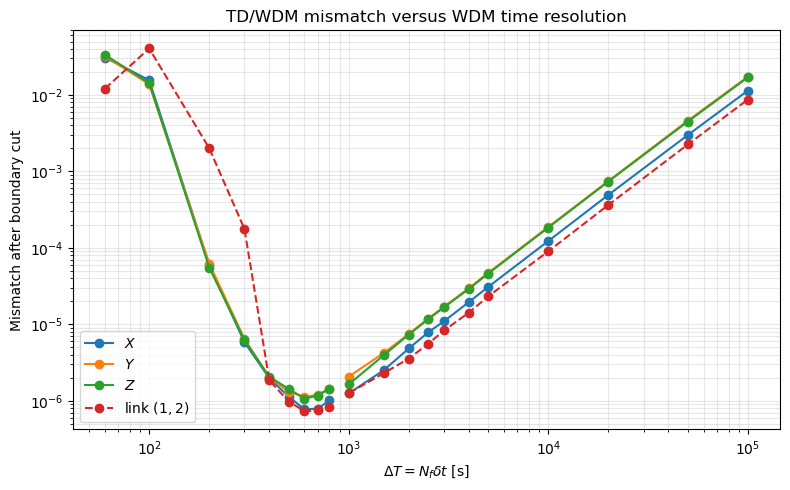

In [16]:
# -------------------------------------------------------------------
# Main plot: mismatch versus DeltaT
# -------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(
    df_deltaT["DeltaT"],
    df_deltaT["X_mismatch_cut"],
    marker="o",
    label=r"$X$",
)

ax.loglog(
    df_deltaT["DeltaT"],
    df_deltaT["Y_mismatch_cut"],
    marker="o",
    label=r"$Y$",
)

ax.loglog(
    df_deltaT["DeltaT"],
    df_deltaT["Z_mismatch_cut"],
    marker="o",
    label=r"$Z$",
)

ax.loglog(
    df_deltaT["DeltaT"],
    df_deltaT["link_12_mismatch_cut"],
    marker="o",
    linestyle="--",
    label=r"link $(1,2)$",
)

ax.set_xlabel(r"$\Delta T = N_f \delta t$ [s]")
ax.set_ylabel("Mismatch after boundary cut")
ax.set_title(r"TD/WDM mismatch versus WDM time resolution")
ax.grid(True, which="both", alpha=0.3)
ax.legend()

fig.tight_layout()

plot_path = DELTA_T_SWEEP_DIR / "deltaT_mismatch_cut_XYZ_link12_up_to_Nf10000.pdf"
fig.savefig(plot_path, bbox_inches="tight")

print("Saved plot to:", plot_path)

plt.show()

In [22]:
_mismatch_audit["calls"] = 0

res90 = run_deltaT_case(90)

print("Mismatch calls:", _mismatch_audit["calls"])
res90


Running Nf=90, DeltaT=9.000000e+02 s
Shift settings:
  backend:        lagfirst_chunked_lagblock
  row_chunk_size: 2048
  lag_block_size: 32
  job_block_size: -
Grid estimate:
  saved length:   3219000
  target length:  3219120
  Nt estimate:    35768
  coeffs/channel: 3,219,120
  direct WDM XYZ stage: 18.437 s
  extracted direct WDM dl_12 from one-arm cache.
  dl_12 extraction stage: 0.000 s
  TD reference WDM transform stage: 3.162 s
Shape check:
  X_td_w:     (35768, 90)
  X_wdm:      (35768, 90)
  dl12_td_w:  (35768, 90)
  dl12_wdm:   (35768, 90)
  cut-info stage: 0.000 s


ValueError: Mismatch failure at X uncut: w1 has NaN/Inf
w1 original: shape=(35768, 90), dtype=float64, finite=0/3219120, nan=3219120, inf=0